<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/4_Logistic_Regression_Business_or_Leisure_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. Logistic Regression: Business or Leisure Bookings

Is a booking a business trip or a leisure trip? The answer is yes or no, coded as **1** or **0**. Predicting a
yes/no answer is called **classification**.

Logistic regression is the standard first model for it: it gives each booking a **probability**, a number between
0 and 1.

- **Part A** (practice data): does a higher fare mean a business trip?
- **Part B** (real data): does booking further ahead mean a leisure trip?

Slides: W3.1, logistic regression.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

## 0. The Sigmoid Function

Logistic regression is built on one curve, the **sigmoid** (also called the logistic function):

$$p = \frac{1}{1 + e^{-z}}$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

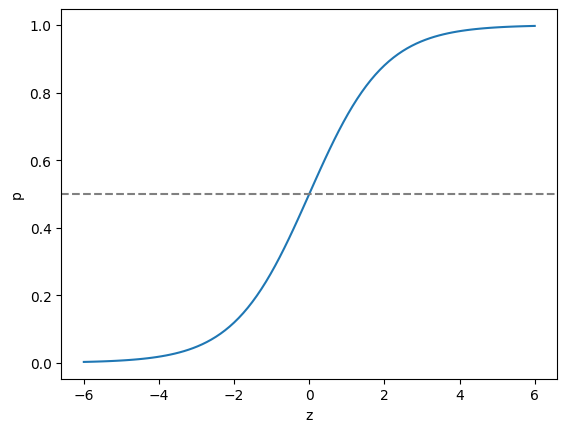

In [2]:
# Figure 1
z = np.linspace(-6, 6, 100)
p = 1 / (1 + np.exp(-z))

plt.plot(z, p)
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('z')
plt.ylabel('p')
plt.show()

In [3]:
z = np.array([-4, 0, 4])
print(np.round(1 / (1 + np.exp(-z)), 3))

[0.018 0.5   0.982]


- $z$ can be **any number**, from very negative to very positive.
- $p$ is **always between 0 and 1**: near 0 for a very negative $z$, exactly **0.5 at $z = 0$**, near 1 for a very
  positive $z$. So $p$ can be read as a probability.

Logistic regression makes $z$ from a straight line, $z = a + b\,x$, and passes it through this curve.

---
## Part A. Practice Data: Fare Paid and Business Trips

> **Data.** 300 made-up bookings for practice: `fare_paid` (dollars) and `business` (1 = business trip,
> 0 = leisure). The same data as the W3.1 slide on binary classification.

In [4]:
fares = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/practice_fares_300.csv')
fares.head()

,fare_paid,business
0,499,1
1,438,1
2,169,0
3,407,0
4,250,0


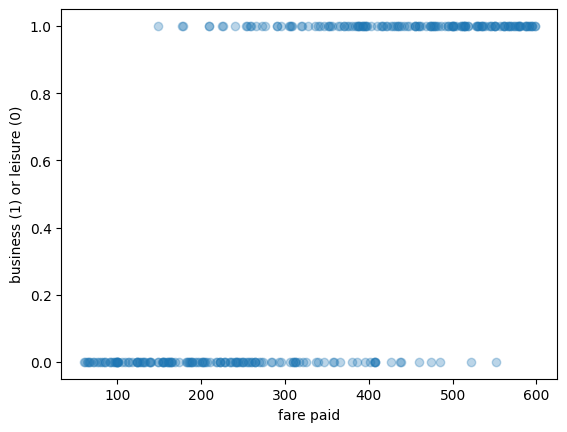

In [5]:
# Figure 2
plt.scatter(fares['fare_paid'], fares['business'], alpha=0.3)
plt.xlabel('fare paid')
plt.ylabel('business (1) or leisure (0)')
plt.show()

### Why not a straight line?

We could fit last week's linear regression to the 0/1 column. Look at what it predicts.

In [6]:
from sklearn.linear_model import LinearRegression

line = LinearRegression()
line.fit(fares[['fare_paid']], fares['business'])

new = pd.DataFrame({'fare_paid': [60, 600]})
print(line.predict(new).round(3))

[-0.113  1.121]


The straight line predicts **-0.113** for a 60-dollar fare and **1.121** for a 600-dollar fare. A probability cannot
be below 0 or above 1, so a straight line is the wrong shape for a yes/no answer.

### Logistic regression

Logistic regression keeps the straight line as a **score** and passes it through the sigmoid from section 0:

$$z = a + b \cdot \text{fare} \qquad\qquad p = \frac{1}{1 + e^{-z}}$$

Here we only want to see the shape, so the model is fit on all 300 bookings. Part B will judge predictions on a
test set.

In [7]:
from sklearn.linear_model import LogisticRegression

logit_a = LogisticRegression()
logit_a.fit(fares[['fare_paid']], fares['business'])

b = logit_a.coef_[0][0]
a = logit_a.intercept_[0]
print('b (per dollar):', round(b, 4))
print('P(business) = 0.5 at a fare of', round(-a / b), 'dollars')

b (per dollar): 0.0153
P(business) = 0.5 at a fare of 326 dollars


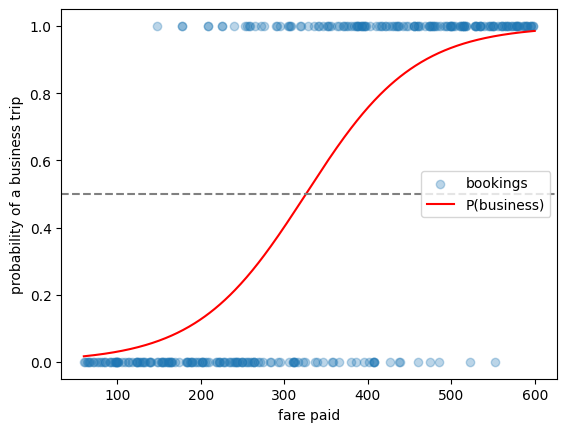

In [8]:
# Figure 3
grid = pd.DataFrame({'fare_paid': np.arange(60, 601)})

plt.scatter(fares['fare_paid'], fares['business'], alpha=0.3, label='bookings')
plt.plot(grid['fare_paid'], logit_a.predict_proba(grid)[:, 1], color='red', label='P(business)')
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('fare paid')
plt.ylabel('probability of a business trip')
plt.legend()
plt.show()

$b$ is **positive** (0.0153), so the higher the fare, the higher the chance of a business trip. The curve is the
sigmoid from section 0: it rises from near 0 to near 1 and crosses 0.5 at about 326 dollars, where $z = 0$.

---
## Part B. Real Data: Days Booked Ahead and Leisure Trips

> **Data.** 983 bookings from 2023, read straight from the course GitHub repository. Only two columns are kept:
> `lead_days` (how many days before departure the trip was booked) and `business` (1 = business trip, 0 = leisure).
> Source: Amadeus air bookings sample, licensed to Embry-Riddle.

This time the question is turned around: **is a booking a leisure trip?** We make a `leisure` column
(1 = leisure, 0 = business).

In [9]:
bookings = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/booking_lead_days.csv')
bookings['leisure'] = 1 - bookings['business']
print(bookings.shape)
bookings.head()

(983, 3)


,lead_days,business,leisure
0,5,1,0
1,120,1,0
2,238,0,1
3,0,0,1
4,64,1,0


In [10]:
# median days booked ahead: 0 = business, 1 = leisure
bookings.groupby('leisure')['lead_days'].median()

leisure
0    28.0
1    75.0
Name: lead_days, dtype: float64

Leisure trips are booked much further ahead (a median of 75 days) than business trips (28 days). So `lead_days`
should help us tell them apart.

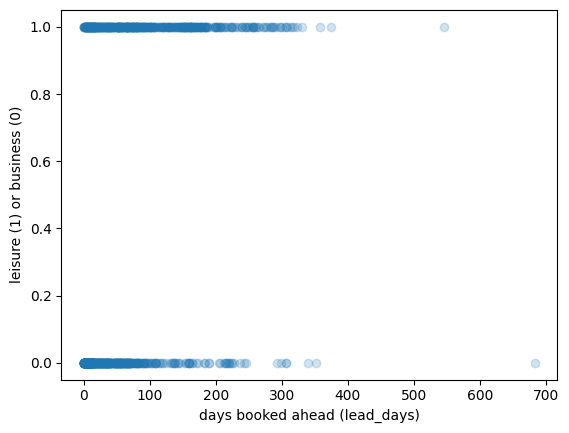

In [11]:
# Figure 4
plt.scatter(bookings['lead_days'], bookings['leisure'], alpha=0.2)
plt.xlabel('days booked ahead (lead_days)')
plt.ylabel('leisure (1) or business (0)')
plt.show()

### Split and train

As in notebook 0, a prediction model is judged on bookings it has not seen. We keep 30% aside as a **test set**.
`stratify=y` keeps the same share of leisure trips in both parts.

In [12]:
from sklearn.model_selection import train_test_split

X = bookings[['lead_days']]
y = bookings['leisure']
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.3, random_state=320, stratify=y)
print('train:', train_X.shape, ' test:', test_X.shape)

train: (688, 1)  test: (295, 1)


In [13]:
logit = LogisticRegression()
logit.fit(train_X, train_y)

b = logit.coef_[0][0]
a = logit.intercept_[0]
print('b (per day):', round(b, 4))
print('a (intercept):', round(a, 3))
print('odds ratio per day:', round(np.exp(b), 4))

b (per day): 0.0099
a (intercept): -0.702
odds ratio per day: 1.0099


**Reading b.** $b$ is positive: the further ahead a trip is booked, the higher the chance it is a leisure trip.
On the odds scale, $e^{b} = 1.0099$: each extra day booked ahead multiplies the odds of a leisure trip by 1.0099
(about 1% higher per day).

### Predicted probabilities

`predict_proba` gives two columns: the probability of class 0 (business) and of class 1 (leisure). We keep the second.

In [14]:
days = pd.DataFrame({'lead_days': [0, 21, 72, 150, 365]})
days['p_leisure'] = logit.predict_proba(days)[:, 1].round(3)
days

,lead_days,p_leisure
0,0,0.331
1,21,0.379
2,72,0.502
3,150,0.685
4,365,0.948


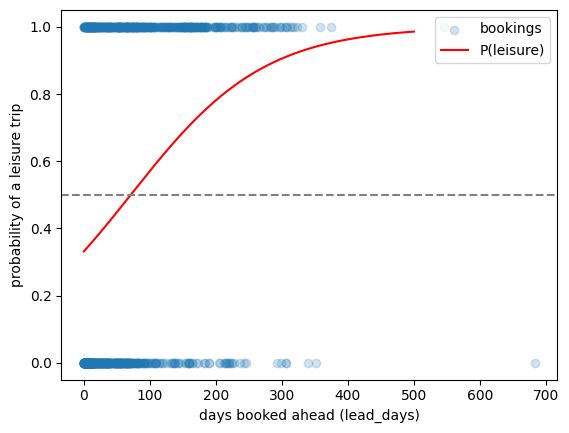

In [15]:
# Figure 5
grid = pd.DataFrame({'lead_days': np.arange(0, 501)})
p = logit.predict_proba(grid)[:, 1]

plt.scatter(bookings['lead_days'], bookings['leisure'], alpha=0.2, label='bookings')
plt.plot(grid['lead_days'], p, color='red', label='P(leisure)')
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('days booked ahead (lead_days)')
plt.ylabel('probability of a leisure trip')
plt.legend()
plt.show()

This is the upper part of the same S-curve: a trip booked on the day of departure is already a leisure trip with
probability 0.331, so the curve starts there instead of near 0.

To turn a probability into a label, the model uses a **cut-off of 0.5**: above it, "leisure"; below it, "business".
The curve crosses 0.5 where the score $z = a + b \cdot \text{days ahead}$ is 0, that is at $-a / b$ days.

In [16]:
print('P(leisure) = 0.5 at', round(-a / b), 'days booked ahead')

P(leisure) = 0.5 at 71 days booked ahead


### How good is it?

**Accuracy** is the share of test bookings the model labels correctly. On its own it means little, so compare it
with a **baseline**: always guessing the larger group.

In [17]:
accuracy = logit.score(test_X, test_y)
baseline = max(test_y.mean(), 1 - test_y.mean())
print('test accuracy:', round(accuracy, 3))
print('baseline (always guess the larger group):', round(baseline, 3))

test accuracy: 0.675
baseline (always guess the larger group): 0.505


In [18]:
from sklearn.metrics import confusion_matrix

# rows: what the booking really was (0 business, 1 leisure); columns: what the model said
confusion_matrix(test_y, logit.predict(test_X))

array([[120,  29],
       [ 67,  79]], dtype=int64)

The **confusion matrix** counts the right and wrong labels. Of 146 leisure trips in the test set, the model
catches 79 and calls the other 67 "business"; of 149 business trips it gets 120 right. One clue (lead time) helps,
but it is not enough to separate the two groups cleanly.

### Your turn

Many airlines sell their cheapest fares only to trips booked at least 21 days ahead. How likely is a booking made
exactly 21 days ahead to be a leisure trip?

1. In the cell below, fill in the blank (`___`) and run it.
2. Then finish this sentence:
   *A trip booked 21 days ahead is a leisure trip with probability ___, so the model labels it ___.*

<details><summary>Show answer</summary>

```python
booking_21 = pd.DataFrame({'lead_days': [21]})
p_21 = logit.predict_proba(booking_21)[0, 1]
print('P(leisure) at 21 days:', round(p_21, 3))
```

*A trip booked 21 days ahead is a leisure trip with probability **0.379**, so the model labels it business (below the 0.5 cut-off).*
</details>

In [ ]:
booking_21 = pd.DataFrame({'lead_days': [___]})
p_21 = logit.predict_proba(booking_21)[0, 1]
print('P(leisure) at 21 days:', round(p_21, 3))

## Summary

| Step | What we found |
|---|---|
| Sigmoid | $p = 1 / (1 + e^{-z})$: any $z$ becomes a number between 0 and 1; 0.5 at $z = 0$ |
| Straight line (Part A) | Predicts impossible values: -0.113 at 60 dollars, 1.121 at 600 dollars |
| Logistic regression (Part A) | $b$ = 0.0153 per dollar, positive: P(business) rises with the fare |
| Real data (Part B) | $b$ = 0.0099 per day, positive: P(leisure) rises with days booked ahead; odds ratio 1.0099 |
| Cut-off 0.5 | Reached at about 71 days booked ahead |
| Test accuracy | 0.675, against 0.505 for always guessing the larger group |

---
# Challenge

1. At how many days booked ahead does the probability of a leisure trip reach 0.75? (Hint: try a few values of
   `lead_days` with `predict_proba`, or solve $z = \log(0.75 / 0.25)$ for `lead_days`.)
2. Lead time alone gives 0.675. What other piece of information in a real booking might help tell business from
   leisure trips? Name two, and say why.

In [20]:
# Your answer